# PBL JS05 - Klasterisasi Hierarki HDBSCAN

**Nama:** Agus
**NIM:** 244107020049

[Sumber modul](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js05-klasterisasi-hierarki)

Notebook ini menerapkan langkah-langkah jobsheet JS05 pada **dataset PBL: Malicious URL Detection**
(`Malicious URL Detection.csv` di root repositori). Dataset berisi 783.705 URL dengan kolom `url` dan `type`, terbagi ke 7 kelas:
`benign`, `legitimate`, `defacement`, `phishing`, `malware`, `spam`, dan `Exploit`.
URL sudah dinormalisasi oleh sumbernya (huruf kecil, tanpa `http(s)://` dan `www.`).
Fungsi muat data dan ekstraksi fitur leksikal ada di modul bersama [`pbl_url.py`](../pbl_url.py), sehingga semua notebook PBL memakai definisi fitur yang sama.

**Pemetaan langkah jobsheet → dataset PBL:**


| Jobsheet JS05 | Penerapan pada URL |
| --- | --- |
| Praktikum 1 - HDBSCAN vs DBSCAN, scale invariance, kepadatan berbeda | URL memiliki kepadatan berbeda: IP-malware rapat, benign tersebar |
| Praktikum 2 - `min_cluster_size`, `min_samples`, silhouette, Davies-Bouldin | Eksperimen hyperparameter pada 10.000 URL |
| Tugas - HDBSCAN pada dataset berlabel, PCA, perbandingan dengan label asli | ARI, NMI, purity, noise per kelas |

In [1]:
import sys, time
from pathlib import Path
sys.path.insert(0, str(Path('..').resolve()))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pbl_url
np.random.seed(42)
print('Kernel:', sys.executable)

Kernel: /Users/jergal/College/machine-learning-smt-5/.venv/bin/python


## Langkah 1 - Memuat dan Menyiapkan Data

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import HDBSCAN, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score, normalized_mutual_info_score
df = pbl_url.load_urls(sample=10000, random_state=7)
X = pbl_url.lexical_features(df['url'])
y = df['type'].to_numpy()
features = ['url_len', 'host_len', 'path_len', 'query_len', 'n_dots', 'n_hyphens', 'n_slashes', 'n_equals',
            'n_digits', 'digit_ratio', 'n_subdomains', 'path_depth', 'is_ip', 'has_php', 'entropy', 'host_entropy']
Xs = StandardScaler().fit_transform(np.log1p(X[features].clip(lower=0)))
P = PCA(2, random_state=42).fit_transform(Xs)
print(Xs.shape, pd.Series(y).value_counts().to_dict())

(10000, 16) {'benign': 5441, 'phishing': 2930, 'defacement': 1216, 'malware': 301, 'legitimate': 74, 'spam': 35, 'Exploit': 3}


Fitur dan transformasi sama dengan PBL JS04 (log1p + standardisasi) agar hasil HDBSCAN dapat dibandingkan langsung dengan KMeans/DBSCAN.
HDBSCAN memakai implementasi `sklearn.cluster.HDBSCAN` (scikit-learn ≥ 1.3), yang mengikuti algoritme Campello dkk. (2013).

## Langkah 2 - Uji scale invariance DBSCAN vs HDBSCAN

In [3]:
def summary(lab):
    return {'n_klaster': len(set(lab)) - (-1 in lab), 'noise_%': round(100 * (lab == -1).mean(), 2)}
rows = []
for scale in [1, 3]:
    rows.append({'skala_data': scale, 'model': 'DBSCAN eps=1.0', **summary(DBSCAN(eps=1.0, min_samples=32).fit_predict(Xs * scale))})
    rows.append({'skala_data': scale, 'model': 'HDBSCAN mcs=50', **summary(HDBSCAN(min_cluster_size=50).fit_predict(Xs * scale))})
pd.DataFrame(rows)

/Users/jergal/College/machine-learning-smt-5/.venv/lib/python3.12/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


/Users/jergal/College/machine-learning-smt-5/.venv/lib/python3.12/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


,skala_data,model,n_klaster,noise_%
0,1,DBSCAN eps=1.0,18,54.70
1,1,HDBSCAN mcs=50,7,26.27
2,3,DBSCAN eps=1.0,3,95.25
3,3,HDBSCAN mcs=50,7,26.27


## Langkah 3 - HDBSCAN pada data berkepadatan berbeda

/Users/jergal/College/machine-learning-smt-5/.venv/lib/python3.12/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


0.4 s {'n_klaster': 21, 'noise_%': np.float64(40.75)}


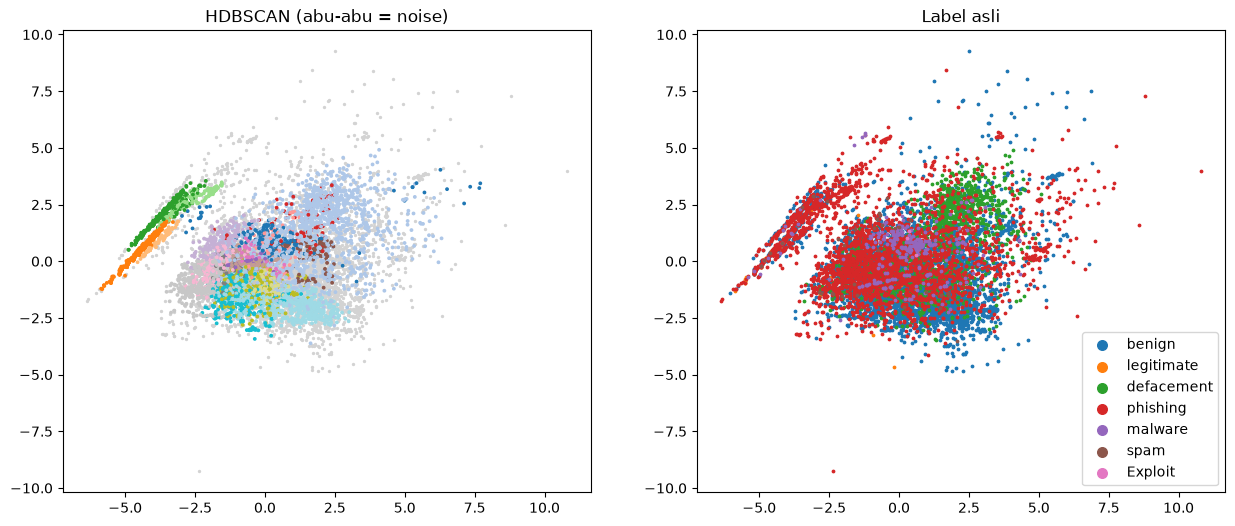

In [4]:
t0 = time.perf_counter()
hdb = HDBSCAN(min_cluster_size=50, min_samples=10).fit(Xs)
lab = hdb.labels_
print(f'{time.perf_counter() - t0:.1f} s', summary(lab))
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
ax[0].scatter(P[lab == -1, 0], P[lab == -1, 1], c='lightgray', s=2)
ax[0].scatter(P[lab != -1, 0], P[lab != -1, 1], c=lab[lab != -1], s=3, cmap='tab20'); ax[0].set_title('HDBSCAN (abu-abu = noise)')
for t in pbl_url.CLASSES:
    m = y == t; ax[1].scatter(P[m, 0], P[m, 1], s=3, label=t)
ax[1].legend(markerscale=4); ax[1].set_title('Label asli'); plt.show()

## Praktikum 2 - Eksperimen `min_cluster_size` dan `min_samples`

In [5]:
def evaluate(lab):
    m = lab != -1
    ok = len(set(lab[m])) > 1
    return {**summary(lab),
            'silhouette': silhouette_score(Xs[m], lab[m]) if ok else np.nan,
            'davies_bouldin': davies_bouldin_score(Xs[m], lab[m]) if ok else np.nan,
            'ARI': adjusted_rand_score(y, lab), 'NMI': normalized_mutual_info_score(y, lab)}
rows = []
for mcs in [25, 50, 100, 200, 400]:
    rows.append({'min_cluster_size': mcs, 'min_samples': 10, **evaluate(HDBSCAN(min_cluster_size=mcs, min_samples=10).fit_predict(Xs))})
for ms in [1, 5, 25, 50]:
    rows.append({'min_cluster_size': 100, 'min_samples': ms, **evaluate(HDBSCAN(min_cluster_size=100, min_samples=ms).fit_predict(Xs))})
grid = pd.DataFrame(rows); grid.round(4)

/Users/jergal/College/machine-learning-smt-5/.venv/lib/python3.12/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


/Users/jergal/College/machine-learning-smt-5/.venv/lib/python3.12/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


/Users/jergal/College/machine-learning-smt-5/.venv/lib/python3.12/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


/Users/jergal/College/machine-learning-smt-5/.venv/lib/python3.12/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


/Users/jergal/College/machine-learning-smt-5/.venv/lib/python3.12/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


/Users/jergal/College/machine-learning-smt-5/.venv/lib/python3.12/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


/Users/jergal/College/machine-learning-smt-5/.venv/lib/python3.12/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


/Users/jergal/College/machine-learning-smt-5/.venv/lib/python3.12/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


/Users/jergal/College/machine-learning-smt-5/.venv/lib/python3.12/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


,min_cluster_size,min_samples,n_klaster,noise_%,silhouette,davies_bouldin,ARI,NMI
0,25,10,33,43.42,0.1690,1.2914,0.0416,0.1176
1,50,10,21,40.75,0.1574,1.5564,0.0363,0.1142
2,100,10,14,30.83,0.1410,1.5747,0.0347,0.1083
3,200,10,6,16.18,0.1718,1.5155,0.0722,0.0902
4,400,10,5,13.72,0.1770,1.5304,0.0957,0.0948
5,100,1,24,26.26,0.1611,1.8812,0.0356,0.1132
6,100,5,21,33.56,0.2102,1.7203,0.0261,0.1176
7,100,25,7,19.99,0.1848,1.3034,0.0732,0.1101
8,100,50,7,26.27,0.1974,1.2486,0.0681,0.1103


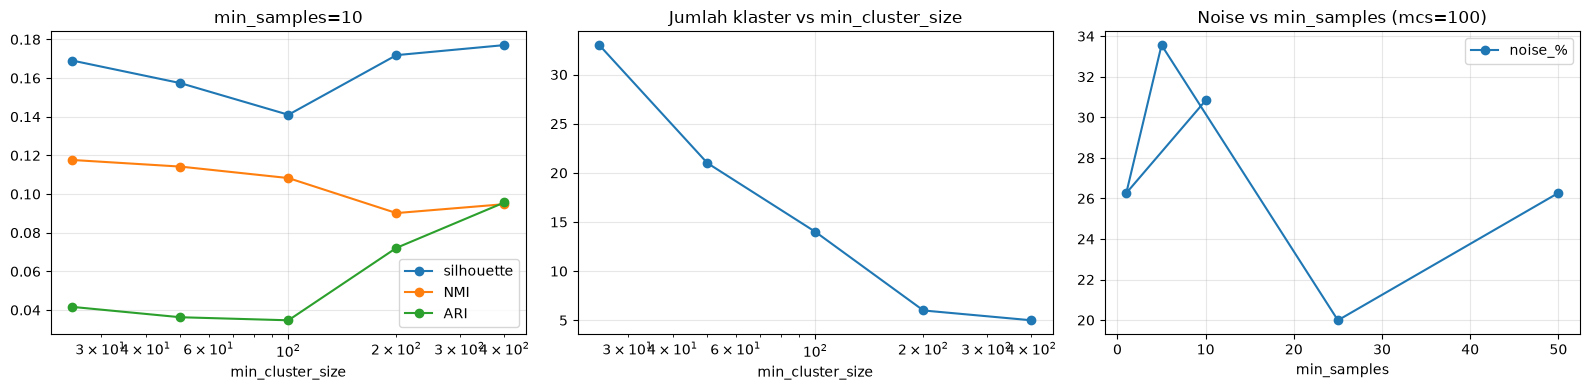

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
g1 = grid[grid['min_samples'] == 10].set_index('min_cluster_size')
g1[['silhouette', 'NMI', 'ARI']].plot(ax=ax[0], marker='o', title='min_samples=10'); ax[0].set_xscale('log')
g1['n_klaster'].plot(ax=ax[1], marker='o', title='Jumlah klaster vs min_cluster_size'); ax[1].set_xscale('log')
g2 = grid[grid['min_cluster_size'] == 100].drop_duplicates('min_samples').set_index('min_samples')
g2[['noise_%']].plot(ax=ax[2], marker='o', title='Noise vs min_samples (mcs=100)')
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## Perbandingan HDBSCAN terbaik (NMI tertinggi) dengan DBSCAN biasa

In [7]:
best = grid.sort_values('NMI', ascending=False).iloc[0]
hdb_best = HDBSCAN(min_cluster_size=int(best['min_cluster_size']), min_samples=int(best['min_samples'])).fit(Xs)
rows = [{'model': f"HDBSCAN mcs={int(best['min_cluster_size'])}, ms={int(best['min_samples'])}", **evaluate(hdb_best.labels_)}]
for eps in [0.5, 1.0, 1.5]:
    rows.append({'model': f'DBSCAN eps={eps}, min_samples=32', **evaluate(DBSCAN(eps=eps, min_samples=32).fit_predict(Xs))})
pd.DataFrame(rows).set_index('model').round(4)

/Users/jergal/College/machine-learning-smt-5/.venv/lib/python3.12/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


,n_klaster,noise_%,silhouette,davies_bouldin,ARI,NMI
model,,,,,,
"HDBSCAN mcs=25, ms=10",33,43.42,0.1690,1.2914,0.0416,0.1176
"DBSCAN eps=0.5, min_samples=32",7,88.93,0.6067,0.4534,-0.0303,0.0443
"DBSCAN eps=1.0, min_samples=32",18,54.70,0.2810,1.1844,-0.0089,0.1086
"DBSCAN eps=1.5, min_samples=32",10,21.28,0.2084,1.2732,0.0815,0.1306


## Tugas - Membandingkan klaster dengan label asli

In [8]:
lab = hdb_best.labels_
ct = pd.crosstab(pd.Series(lab, name='klaster'), pd.Series(y, name='type'))
purity = ct.drop(index=-1, errors='ignore').max(axis=1).sum() / (lab != -1).sum()
print(f'Purity klaster (tanpa noise): {purity:.4f}')
print('Noise per kelas (%):', (pd.Series(lab == -1).groupby(y).mean() * 100).round(1).to_dict())
dom = ct.drop(index=-1, errors='ignore').idxmax(axis=1).value_counts()
print('Kelas dominan per klaster:', dom.to_dict())
big = ct.drop(index=-1, errors='ignore').sum(axis=1).sort_values(ascending=False).index[:10]
ct.loc[[-1] + list(big)] if -1 in ct.index else ct.loc[list(big)]

Purity klaster (tanpa noise): 0.6221
Noise per kelas (%): {'Exploit': 0.0, 'benign': 46.8, 'defacement': 29.6, 'legitimate': 12.2, 'malware': 26.2, 'phishing': 45.5, 'spam': 48.6}
Kelas dominan per klaster: {'benign': 23, 'phishing': 8, 'malware': 1, 'defacement': 1}


type,Exploit,benign,defacement,legitimate,malware,phishing,spam
klaster,,,,,,,
-1,0,2544,360,9,79,1333,17
1,0,340,617,0,8,365,1
3,0,337,0,55,9,173,4
28,0,286,11,0,14,105,1
23,0,217,29,2,22,102,0
27,0,162,7,1,0,98,4
8,0,134,0,4,3,116,2
29,0,168,30,0,0,29,0
19,0,106,53,2,2,54,0


## Analisis

**Scale invariance.** Ketika data dikalikan 3, DBSCAN dengan `eps` = 1,0 berubah drastis: noise naik dari 54,7% ke 95,3%, dan jumlah klaster turun dari 18 ke 3. HDBSCAN tetap persis sama (7 klaster, noise 26,27%). HDBSCAN tidak memakai ambang jarak global. Ia membangun hierarki dari *mutual reachability distance* lalu memilih klaster yang paling stabil (Campello dkk., 2013), sehingga hasilnya tidak bergantung pada satuan jarak.

**Hyperparameter.**
* Menaikkan `min_cluster_size` (25 → 400) mengurangi jumlah klaster (33 → 5) dan noise (43% → 14%). ARI naik ke 0,096 karena klaster besar lebih mendekati kelas mayoritas, tetapi NMI turun dari 0,118 ke 0,095.
* `min_samples` mengatur seberapa konservatif klaster terbentuk. Nilai 1 menghasilkan 24 klaster dan noise 26%. Nilai 5 menghasilkan silhouette tertinggi (0,210) tetapi noise 34%. Nilai 50 memberi Davies-Bouldin terbaik (1,249).
* Tidak ada konfigurasi yang unggul di semua metrik. Silhouette 0,14-0,21 dan DBI 1,25-1,88 menunjukkan struktur klaster yang lemah, konsisten dengan PBL JS04.

**HDBSCAN vs DBSCAN.** DBSCAN dengan `eps` = 0,5 memiliki silhouette tertinggi (0,607) dan DBI terendah (0,453), tetapi dengan **noise 88,9%**. Metrik internal ini hanya dihitung pada 11% titik yang paling rapat, sehingga terlihat menyesatkan baik. ARI-nya juga negatif (-0,03), lebih buruk daripada acak. Pada `eps` = 1,5 (noise 21%), DBSCAN memberi NMI 0,131, sedikit di atas HDBSCAN terbaik (0,118). Jadi keunggulan HDBSCAN pada data ini terletak pada **ketahanan terhadap skala dan tidak perlunya memilih `eps`**, bukan pada kesesuaian dengan label.

**Dibandingkan dengan label asli (HDBSCAN `min_cluster_size` = 25, `min_samples` = 10):** purity klaster tanpa noise adalah 0,622. Sebanyak 23 dari 33 klaster didominasi benign, 8 oleh phishing, 1 oleh malware, dan 1 oleh defacement.
* Klaster 0 berisi **seluruh Exploit** dan 136 malware (URL ke alamat IP). Noise untuk Exploit 0%, artinya pola IP + berkas biner adalah kelompok paling padat dan konsisten.
* Klaster 1 berisi 617 defacement (pola Joomla `index.php?option=`).
* Noise terbesar ada pada benign (46,8%), spam (48,6%), dan phishing (45,5%). URL di kelas-kelas ini paling beragam, sehingga tidak membentuk wilayah padat. Bagi HDBSCAN, sebagian besar URL phishing adalah *outlier*, bukan anggota pola yang konsisten.

McInnes dkk. (2017) merekomendasikan HDBSCAN untuk eksplorasi karena noise eksplisit lebih jujur daripada memaksa setiap titik masuk klaster. Di sini, noise ~40% justru menjadi informasi bahwa fitur leksikal saja tidak cukup untuk memisahkan phishing dari benign tanpa label.

## Rujukan

1. Campello, R. J. G. B., Moulavi, D., & Sander, J. (2013). Density-based clustering based on hierarchical density estimates. *Advances in Knowledge Discovery and Data Mining (PAKDD 2013)*, LNCS 7819, 160-172. https://doi.org/10.1007/978-3-642-37456-2_14
2. McInnes, L., Healy, J., & Astels, S. (2017). hdbscan: Hierarchical density based clustering. *Journal of Open Source Software*, 2(11), 205. https://doi.org/10.21105/joss.00205
3. Ester, M., Kriegel, H.-P., Sander, J., & Xu, X. (1996). A density-based algorithm for discovering clusters in large spatial databases with noise. *Proceedings of the 2nd International Conference on Knowledge Discovery and Data Mining (KDD)*, 226-231.
4. Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics*, 20, 53-65. https://doi.org/10.1016/0377-0427(87)90125-7
5. Davies, D. L., & Bouldin, D. W. (1979). A cluster separation measure. *IEEE Transactions on Pattern Analysis and Machine Intelligence*, PAMI-1(2), 224-227. https://doi.org/10.1109/TPAMI.1979.4766909
6. Hubert, L., & Arabie, P. (1985). Comparing partitions. *Journal of Classification*, 2(1), 193-218. https://doi.org/10.1007/BF01908075
7. Ma, J., Saul, L. K., Savage, S., & Voelker, G. M. (2009). Beyond blacklists: Learning to detect malicious web sites from suspicious URLs. *Proceedings of the 15th ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 1245-1254. https://doi.org/10.1145/1557019.1557153